In [2]:
from google.colab import drive
drive.mount('/content/drive')
# Importing Required Python libraries

import pandas as pd # dataset handle korbo
import matplotlib.pyplot as plt # plot korbo
import seaborn as sns # correlation

# loading dataset
dataset = pd.read_csv("/content/drive/MyDrive/Cse 111/Career_Switch_Prediction_Dataset.csv")

Mounted at /content/drive


### **Summarize data**

In [3]:
dataset.head(10)

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,will_change_career
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,0,83,0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,0,52,1
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0
5,21651,city_176,0.764,NaN,Has relevent experience,Part time course,Graduate,STEM,11,NaN,NaN,1,24,1
6,28806,city_160,0.920,Male,Has relevent experience,no_enrollment,High School,NaN,5,50-99,Funded Startup,1,24,0
7,402,city_46,0.762,Male,Has relevent experience,no_enrollment,Graduate,STEM,13,<10,Pvt Ltd,>4,18,1
8,27107,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,7,50-99,Pvt Ltd,1,46,1
9,699,city_103,0.920,NaN,Has relevent experience,no_enrollment,Graduate,STEM,17,10000+,Pvt Ltd,>4,123,0


In [4]:
print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

Shape of the dataset is (5000, 14). This dataset contains 5000 rows and 14 columns.


### **Feature Names and its Datatypes**

In [5]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             5000 non-null   int64  
 1   city                    5000 non-null   object 
 2   city_development_index  5000 non-null   float64
 3   gender                  3887 non-null   object 
 4   relevent_experience     5000 non-null   object 
 5   enrolled_university     4893 non-null   object 
 6   education_level         4882 non-null   object 
 7   major_discipline        4276 non-null   object 
 8   experience              4989 non-null   object 
 9   company_size            3429 non-null   object 
 10  company_type            3379 non-null   object 
 11  last_new_job            4896 non-null   object 
 12  training_hours          5000 non-null   int64  
 13  will_change_career      5000 non-null   int64  
dtypes: float64(1), int64(3), object(10)
memo

### **Data Spliting**
#### Select and separately store Numerical and Categorical features in different variables.

In [6]:
#### selecting numerical features
numerical_data = dataset.select_dtypes(include='number')
numerical_features=numerical_data.columns.tolist()

print(f'There are {len(numerical_features)} numerical features:', '\n')
print(numerical_features)

There are 4 numerical features: 

['enrollee_id', 'city_development_index', 'training_hours', 'will_change_career']


In [7]:
#Selecting categoricalfeatures
categorical_data=dataset.select_dtypes(include= 'object')
categorical_features=categorical_data.columns.tolist()

print(f'There are {len(categorical_features)} categorical features:', '\n')
print(categorical_features)

There are 10 categorical features: 

['city', 'gender', 'relevent_experience', 'enrolled_university', 'education_level', 'major_discipline', 'experience', 'company_size', 'company_type', 'last_new_job']


Filling the missing values:

numerical features -> mean if skew[feature] < 0.5 else median

categorical features -> by mode

In [8]:
## Filling numerical missing values
skewness = dataset.skew(numeric_only=True)
print(skewness)

for feature in numerical_features:
  skew_val = dataset[feature].skew()
  if abs(skew_val) < 0.5:
    # mean
    dataset[feature] = dataset[feature].fillna(dataset[feature].mean())
  else:
    # median
    dataset[feature] = dataset[feature].fillna(dataset[feature].median())

enrollee_id              -0.022808
city_development_index   -1.013328
training_hours            1.853677
will_change_career        1.140333
dtype: float64


In [9]:
## filling categorical missing values
for feature in categorical_features:
  dataset[feature] = dataset[feature].fillna(dataset[feature].mode()[0])

In [10]:
dataset.head(15)

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,will_change_career
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,50-99,Pvt Ltd,1,36,1
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0
2,11561,city_21,0.624,Male,No relevent experience,Full time course,Graduate,STEM,5,50-99,Pvt Ltd,0,83,0
3,33241,city_115,0.789,Male,No relevent experience,no_enrollment,Graduate,Business Degree,<1,50-99,Pvt Ltd,0,52,1
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0
5,21651,city_176,0.764,Male,Has relevent experience,Part time course,Graduate,STEM,11,50-99,Pvt Ltd,1,24,1
6,28806,city_160,0.920,Male,Has relevent experience,no_enrollment,High School,STEM,5,50-99,Funded Startup,1,24,0
7,402,city_46,0.762,Male,Has relevent experience,no_enrollment,Graduate,STEM,13,<10,Pvt Ltd,>4,18,1
8,27107,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,7,50-99,Pvt Ltd,1,46,1
9,699,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,17,10000+,Pvt Ltd,>4,123,0


## Feature Engineering

There are several types:


1.   Categorical Encoding
2.   Engineering Numerical Features



### Categorical Encoding

Therea are two options:


1.   Data with heirarchy / ranking - LabelEncoder() , map()
2.   Data without heirarchy / ranking - One hot Encoding


**Option 1: Data With heirarchy**

Normally values such as Yes/No,  T/F, Positive/Negative, or any binary or multiclass labels

**Option 2: Data without Heirachy**

Normally names of places, cities, countries,

In [11]:
dataset['gender'].unique()

array(['Male', 'Female', 'Other'], dtype=object)

In [12]:
# 1. gender = nominal; hence one hot encoding
dataset = pd.get_dummies(dataset, columns=['gender'], drop_first=False)
dataset.head()

print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

Shape of the dataset is (5000, 16). This dataset contains 5000 rows and 16 columns.


In [13]:
dataset['relevent_experience'].unique()

array(['Has relevent experience', 'No relevent experience'], dtype=object)

In [14]:
# 2. relevent_experience = nominal, HENCE one hot encoding
dataset = pd.get_dummies(dataset, columns=['relevent_experience'], drop_first=False)
dataset.head()

print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

Shape of the dataset is (5000, 17). This dataset contains 5000 rows and 17 columns.


In [15]:
dataset['enrolled_university'].unique()

array(['no_enrollment', 'Full time course', 'Part time course'],
      dtype=object)

In [16]:
# 3. enrolled_university = nominal, hence one hot encoding:
dataset = pd.get_dummies(dataset, columns=['enrolled_university'], drop_first=False)
dataset.head()

print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

Shape of the dataset is (5000, 19). This dataset contains 5000 rows and 19 columns.


In [17]:
dataset['education_level'].unique()

array(['Graduate', 'Masters', 'High School', 'Phd', 'Primary School'],
      dtype=object)

In [18]:
# 4. education_level = ordinal, hence map()
dataset['education_level_enc'] = dataset['education_level'].map({'Primary School': 0, 'High School': 1, 'Graduate': 2, 'Masters': 3, 'Phd': 4})
print(dataset[['education_level', 'education_level_enc']].head(40))

print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

   education_level  education_level_enc
0         Graduate                    2
1         Graduate                    2
2         Graduate                    2
3         Graduate                    2
4          Masters                    3
5         Graduate                    2
6      High School                    1
7         Graduate                    2
8         Graduate                    2
9         Graduate                    2
10     High School                    1
11        Graduate                    2
12        Graduate                    2
13        Graduate                    2
14     High School                    1
15        Graduate                    2
16        Graduate                    2
17        Graduate                    2
18        Graduate                    2
19        Graduate                    2
20         Masters                    3
21         Masters                    3
22         Masters                    3
23        Graduate                    2


In [19]:
dataset['major_discipline'].unique()

array(['STEM', 'Business Degree', 'Arts', 'Humanities', 'No Major',
       'Other'], dtype=object)

In [20]:
# 5. major_discipline = nominal, hence one hot encoding
dataset = pd.get_dummies(dataset, columns=['major_discipline'], drop_first=False)
dataset.head()

print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

Shape of the dataset is (5000, 25). This dataset contains 5000 rows and 25 columns.


In [21]:
dataset['company_type'].unique()

array(['Pvt Ltd', 'Funded Startup', 'Early Stage Startup', 'Other',
       'Public Sector', 'NGO'], dtype=object)

In [22]:
# 6. company_type = nominal, hence one hot encoding
dataset = pd.get_dummies(dataset, columns=['company_type'], drop_first=False)
dataset.head()

print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

Shape of the dataset is (5000, 30). This dataset contains 5000 rows and 30 columns.


In [23]:
dataset['experience'].unique()

array(['>20', '15', '5', '<1', '11', '13', '7', '17', '2', '16', '1', '4',
       '10', '14', '18', '19', '12', '3', '6', '9', '8', '20'],
      dtype=object)

In [24]:
# 7. experience is ordinal BUT ALPHABETIC ORDER OF LABELENCODER() WILL BE UNORDERED
## hence I use map()
exp_map = {
    '<1': 0,
    '1': 1,
    '2': 2,
    '3': 3,
    '4': 4,
    '5': 5,
    '6': 6,
    '7': 7,
    '8': 8,
    '9': 9,
    '10': 10,
    '11': 11,
    '12': 12,
    '13': 13,
    '14': 14,
    '15': 15,
    '16': 16,
    '17': 17,
    '18': 18,
    '19': 19,
    '20': 20,
    '>20': 21
}

dataset['experience_enc'] = dataset['experience'].map(exp_map)

print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

Shape of the dataset is (5000, 31). This dataset contains 5000 rows and 31 columns.


In [25]:
dataset["last_new_job"].unique()

array(['1', '>4', '0', '4', '3', '2'], dtype=object)

In [26]:
# 8. last_new_job = ordinal, but labelencoder gives unordered due to
## order, hence map()
job_map = {
    '0': 0,
    '1': 1,
    '2': 2,
    '3': 3,
    '4': 4,
    '>4': 5,
}

dataset['last_new_job_enc'] = dataset['last_new_job'].map(job_map)

print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

Shape of the dataset is (5000, 32). This dataset contains 5000 rows and 32 columns.


In [27]:
dataset["last_new_job_enc"]

,last_new_job_enc
0,1
1,5
2,0
3,0
4,4
...,...
4995,1
4996,1
4997,5
4998,5


# **corrupt value found in feature: company_size**
replace these values by mode

In [28]:
# 9. company_size
# checking how datapoints of company_size have corrput values

import pandas as pd

# Step 1: Check how many rows contain 'oct-49' in company_size
oct49_rows = dataset[dataset['company_size'] == 'Oct-49']
num_oct49 = len(oct49_rows)

# Step 2: Print the number and inspect the rows
print(f"Number of rows with 'Oct-49' in company_size: {num_oct49}")
print(oct49_rows)


Number of rows with 'Oct-49' in company_size: 376
      enrollee_id      city  city_development_index education_level  \
15           6588  city_114                   0.926        Graduate   
35           4866  city_103                   0.920        Graduate   
41          13854  city_104                   0.924     High School   
49          25103   city_83                   0.923        Graduate   
58          13478   city_21                   0.624        Graduate   
...           ...       ...                     ...             ...   
4964         7099   city_16                   0.910        Graduate   
4974         4712   city_67                   0.855        Graduate   
4980         1990   city_21                   0.624        Graduate   
4983        31589   city_16                   0.910        Graduate   
4987          558  city_173                   0.878  Primary School   

     experience company_size last_new_job  training_hours  will_change_career  \
15           16 

In [29]:
dataset['company_size'].unique()

array(['50-99', '<10', '10000+', '5000-9999', '1000-4999', 'Oct-49',
       '100-500', '500-999'], dtype=object)

In [30]:
# Step 1: Find the mode of valid (non-corrupt) company_size entries
valid_mode = dataset.loc[dataset['company_size'] != 'Oct-49', 'company_size'].mode()[0]

# Step 2: Replace 'Oct-49' with the mode value
dataset['company_size'] = dataset['company_size'].replace('Oct-49', valid_mode)
dataset['company_size_enc'] = dataset['company_size'].map({'<10': 1, '10-49': 2, '50-99': 3, '100-500': 4, '500-999': 5, '1000-4999': 6, '5000-9999': 7, '10000+': 8})

print(dataset[['company_size', 'company_size_enc']].head(49))

   company_size  company_size_enc
0         50-99                 3
1         50-99                 3
2         50-99                 3
3         50-99                 3
4         50-99                 3
5         50-99                 3
6         50-99                 3
7           <10                 1
8         50-99                 3
9        10000+                 8
10        50-99                 3
11    5000-9999                 7
12    1000-4999                 6
13        50-99                 3
14        50-99                 3
15        50-99                 3
16        50-99                 3
17    5000-9999                 7
18       10000+                 8
19        50-99                 3
20      100-500                 4
21      100-500                 4
22        50-99                 3
23    1000-4999                 6
24    1000-4999                 6
25        50-99                 3
26      500-999                 5
27        50-99                 3
28          <1

In [31]:
dataset["city"].unique()

array(['city_103', 'city_40', 'city_21', 'city_115', 'city_162',
       'city_176', 'city_160', 'city_46', 'city_61', 'city_114',
       'city_13', 'city_159', 'city_102', 'city_67', 'city_100',
       'city_16', 'city_71', 'city_104', 'city_64', 'city_101', 'city_83',
       'city_105', 'city_73', 'city_75', 'city_41', 'city_11', 'city_93',
       'city_90', 'city_36', 'city_20', 'city_57', 'city_152', 'city_19',
       'city_65', 'city_74', 'city_173', 'city_136', 'city_98', 'city_97',
       'city_50', 'city_138', 'city_82', 'city_157', 'city_89',
       'city_150', 'city_70', 'city_175', 'city_94', 'city_28', 'city_59',
       'city_165', 'city_145', 'city_142', 'city_26', 'city_12',
       'city_37', 'city_43', 'city_116', 'city_23', 'city_99', 'city_149',
       'city_10', 'city_45', 'city_80', 'city_128', 'city_158',
       'city_123', 'city_7', 'city_72', 'city_106', 'city_143', 'city_78',
       'city_109', 'city_24', 'city_134', 'city_48', 'city_144',
       'city_91', 'city_

In [32]:
# 10. city = nominal BUT CATEGORICAL COLS = 170+, HENCE label_Encoder()
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
dataset['city_enc'] = le.fit_transform(dataset['city'])

print(dataset['city'].unique())
print(dataset[['city', 'city_enc']].head(20))

print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

['city_103' 'city_40' 'city_21' 'city_115' 'city_162' 'city_176'
 'city_160' 'city_46' 'city_61' 'city_114' 'city_13' 'city_159' 'city_102'
 'city_67' 'city_100' 'city_16' 'city_71' 'city_104' 'city_64' 'city_101'
 'city_83' 'city_105' 'city_73' 'city_75' 'city_41' 'city_11' 'city_93'
 'city_90' 'city_36' 'city_20' 'city_57' 'city_152' 'city_19' 'city_65'
 'city_74' 'city_173' 'city_136' 'city_98' 'city_97' 'city_50' 'city_138'
 'city_82' 'city_157' 'city_89' 'city_150' 'city_70' 'city_175' 'city_94'
 'city_28' 'city_59' 'city_165' 'city_145' 'city_142' 'city_26' 'city_12'
 'city_37' 'city_43' 'city_116' 'city_23' 'city_99' 'city_149' 'city_10'
 'city_45' 'city_80' 'city_128' 'city_158' 'city_123' 'city_7' 'city_72'
 'city_106' 'city_143' 'city_78' 'city_109' 'city_24' 'city_134' 'city_48'
 'city_144' 'city_91' 'city_146' 'city_133' 'city_126' 'city_118' 'city_9'
 'city_167' 'city_27' 'city_84' 'city_54' 'city_39' 'city_79' 'city_76'
 'city_77' 'city_81' 'city_131' 'city_44' 'city_117'

In [33]:
print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

Shape of the dataset is (5000, 34). This dataset contains 5000 rows and 34 columns.


In [34]:
dataset.head(10)

,enrollee_id,city,city_development_index,education_level,experience,company_size,last_new_job,training_hours,will_change_career,gender_Female,...,company_type_Early Stage Startup,company_type_Funded Startup,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd,experience_enc,last_new_job_enc,company_size_enc,city_enc
0,8949,city_103,0.920,Graduate,>20,50-99,1,36,1,False,...,False,False,False,False,False,True,21,1,3,5
1,29725,city_40,0.776,Graduate,15,50-99,>4,47,0,False,...,False,False,False,False,False,True,15,5,3,68
2,11561,city_21,0.624,Graduate,5,50-99,0,83,0,False,...,False,False,False,False,False,True,5,0,3,56
3,33241,city_115,0.789,Graduate,<1,50-99,0,52,1,False,...,False,False,False,False,False,True,0,0,3,13
4,666,city_162,0.767,Masters,>20,50-99,4,8,0,False,...,False,True,False,False,False,False,21,4,3,46
5,21651,city_176,0.764,Graduate,11,50-99,1,24,1,False,...,False,False,False,False,False,True,11,1,3,51
6,28806,city_160,0.920,High School,5,50-99,1,24,0,False,...,False,True,False,False,False,False,5,1,3,45
7,402,city_46,0.762,Graduate,13,<10,>4,18,1,False,...,False,False,False,False,False,True,13,5,1,74
8,27107,city_103,0.920,Graduate,7,50-99,1,46,1,False,...,False,False,False,False,False,True,7,1,3,5
9,699,city_103,0.920,Graduate,17,10000+,>4,123,0,False,...,False,False,False,False,False,True,17,5,8,5


# Dropping those categorical features which I have done one hot encoding cuz I have the corresponding encoded new features of these

In [35]:
categorical_features = [
    'education_level',
    'company_size',
    'last_new_job',
    'city',
    'experience'
]
dataset = dataset.drop(columns=categorical_features)

In [36]:
dataset.head(10)

,enrollee_id,city_development_index,training_hours,will_change_career,gender_Female,gender_Male,gender_Other,relevent_experience_Has relevent experience,relevent_experience_No relevent experience,enrolled_university_Full time course,...,company_type_Early Stage Startup,company_type_Funded Startup,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd,experience_enc,last_new_job_enc,company_size_enc,city_enc
0,8949,0.920,36,1,False,True,False,True,False,False,...,False,False,False,False,False,True,21,1,3,5
1,29725,0.776,47,0,False,True,False,False,True,False,...,False,False,False,False,False,True,15,5,3,68
2,11561,0.624,83,0,False,True,False,False,True,True,...,False,False,False,False,False,True,5,0,3,56
3,33241,0.789,52,1,False,True,False,False,True,False,...,False,False,False,False,False,True,0,0,3,13
4,666,0.767,8,0,False,True,False,True,False,False,...,False,True,False,False,False,False,21,4,3,46
5,21651,0.764,24,1,False,True,False,True,False,False,...,False,False,False,False,False,True,11,1,3,51
6,28806,0.920,24,0,False,True,False,True,False,False,...,False,True,False,False,False,False,5,1,3,45
7,402,0.762,18,1,False,True,False,True,False,False,...,False,False,False,False,False,True,13,5,1,74
8,27107,0.920,46,1,False,True,False,True,False,False,...,False,False,False,False,False,True,7,1,3,5
9,699,0.920,123,0,False,True,False,True,False,False,...,False,False,False,False,False,True,17,5,8,5


In [37]:
# shifting will_change_career to the last column
target = dataset.pop('will_change_career')
dataset['will_change_career'] = target

dataset.head()

,enrollee_id,city_development_index,training_hours,gender_Female,gender_Male,gender_Other,relevent_experience_Has relevent experience,relevent_experience_No relevent experience,enrolled_university_Full time course,enrolled_university_Part time course,...,company_type_Funded Startup,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd,experience_enc,last_new_job_enc,company_size_enc,city_enc,will_change_career
0,8949,0.920,36,False,True,False,True,False,False,False,...,False,False,False,False,True,21,1,3,5,1
1,29725,0.776,47,False,True,False,False,True,False,False,...,False,False,False,False,True,15,5,3,68,0
2,11561,0.624,83,False,True,False,False,True,True,False,...,False,False,False,False,True,5,0,3,56,0
3,33241,0.789,52,False,True,False,False,True,False,False,...,False,False,False,False,True,0,0,3,13,1
4,666,0.767,8,False,True,False,True,False,False,False,...,True,False,False,False,False,21,4,3,46,0


In [38]:
dataset

,enrollee_id,city_development_index,training_hours,gender_Female,gender_Male,gender_Other,relevent_experience_Has relevent experience,relevent_experience_No relevent experience,enrolled_university_Full time course,enrolled_university_Part time course,...,company_type_Funded Startup,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd,experience_enc,last_new_job_enc,company_size_enc,city_enc,will_change_career
0,8949,0.920,36,False,True,False,True,False,False,False,...,False,False,False,False,True,21,1,3,5,1
1,29725,0.776,47,False,True,False,False,True,False,False,...,False,False,False,False,True,15,5,3,68,0
2,11561,0.624,83,False,True,False,False,True,True,False,...,False,False,False,False,True,5,0,3,56,0
3,33241,0.789,52,False,True,False,False,True,False,False,...,False,False,False,False,True,0,0,3,13,1
4,666,0.767,8,False,True,False,True,False,False,False,...,True,False,False,False,False,21,4,3,46,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,7892,0.624,114,True,False,False,True,False,False,False,...,False,False,False,False,True,3,1,4,56,1
4996,19768,0.624,64,False,True,False,False,True,False,False,...,False,False,False,False,True,3,1,4,56,1
4997,33180,0.910,89,False,True,False,False,True,False,False,...,False,False,False,False,True,21,5,7,44,0
4998,13215,0.920,20,True,False,False,True,False,False,False,...,False,False,False,False,True,10,5,8,5,1


In [39]:
print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

Shape of the dataset is (5000, 29). This dataset contains 5000 rows and 29 columns.


# **Converting dataset to csv **

In [40]:
# dataset.to_csv("engineered_dataset.csv", index=False)
# # download
# from google.colab import files
# files.download("engineered_dataset.csv")

# **Correlation: to decide which column I can remove**

In [41]:
dataset_corr = dataset.corr()
dataset_corr

,enrollee_id,city_development_index,training_hours,gender_Female,gender_Male,gender_Other,relevent_experience_Has relevent experience,relevent_experience_No relevent experience,enrolled_university_Full time course,enrolled_university_Part time course,...,company_type_Funded Startup,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd,experience_enc,last_new_job_enc,company_size_enc,city_enc,will_change_career
enrollee_id,1.000000,-0.039610,-0.004381,0.017773,-0.016512,-0.000307,-0.056828,0.056828,0.032669,-0.002879,...,-0.035046,0.000476,0.002504,0.008406,0.025404,-0.030384,-0.021342,0.029571,-0.012366,0.049445
city_development_index,-0.039610,1.000000,0.004717,0.025067,-0.035241,0.031090,0.075128,-0.075128,-0.178266,-0.017634,...,0.036722,0.032653,0.012228,0.059861,-0.058528,0.331010,0.186799,0.085432,-0.316671,-0.346808
training_hours,-0.004381,0.004717,1.000000,0.003244,0.000269,-0.008713,0.020138,-0.020138,-0.019593,0.001606,...,-0.014537,0.016517,0.020042,-0.022695,-0.001754,-0.005245,0.005942,-0.010959,0.008549,-0.022170
gender_Female,0.017773,0.025067,0.003244,1.000000,-0.925384,-0.026941,-0.021098,0.021098,-0.023361,0.005909,...,0.014524,0.044082,-0.009106,0.021727,-0.035685,-0.038223,0.022741,0.011422,-0.006473,0.016640
gender_Male,-0.016512,-0.035241,0.000269,-0.925384,1.000000,-0.353961,0.032676,-0.032676,0.019049,-0.011992,...,-0.017108,-0.038974,0.011408,-0.023110,0.036520,0.044214,-0.012640,-0.008885,0.002236,-0.010577
gender_Other,-0.000307,0.031090,-0.008713,-0.026941,-0.353961,1.000000,-0.034118,0.034118,0.007406,0.017046,...,0.009281,-0.005985,-0.007618,0.007337,-0.008265,-0.022291,-0.022780,-0.004750,0.010075,-0.013162
relevent_experience_Has relevent experience,-0.056828,0.075128,0.020138,-0.021098,0.032676,-0.034118,1.000000,-1.000000,-0.379365,-0.022450,...,0.105824,0.019701,0.022978,-0.050608,-0.077162,0.347880,0.265971,0.109957,-0.002909,-0.112887
relevent_experience_No relevent experience,0.056828,-0.075128,-0.020138,0.021098,-0.032676,0.034118,-1.000000,1.000000,0.379365,0.022450,...,-0.105824,-0.019701,-0.022978,0.050608,0.077162,-0.347880,-0.265971,-0.109957,0.002909,0.112887
enrolled_university_Full time course,0.032669,-0.178266,-0.019593,-0.023361,0.019049,0.007406,-0.379365,0.379365,1.000000,-0.127005,...,-0.072128,-0.018852,-0.005054,0.028279,0.036724,-0.313918,-0.235225,-0.119028,0.081065,0.148369
enrolled_university_Part time course,-0.002879,-0.017634,0.001606,0.005909,-0.011992,0.017046,-0.022450,0.022450,-0.127005,1.000000,...,0.000881,0.046862,-0.007312,0.008752,-0.028439,-0.073234,-0.024899,-0.012154,0.053715,0.007933


<Axes: >

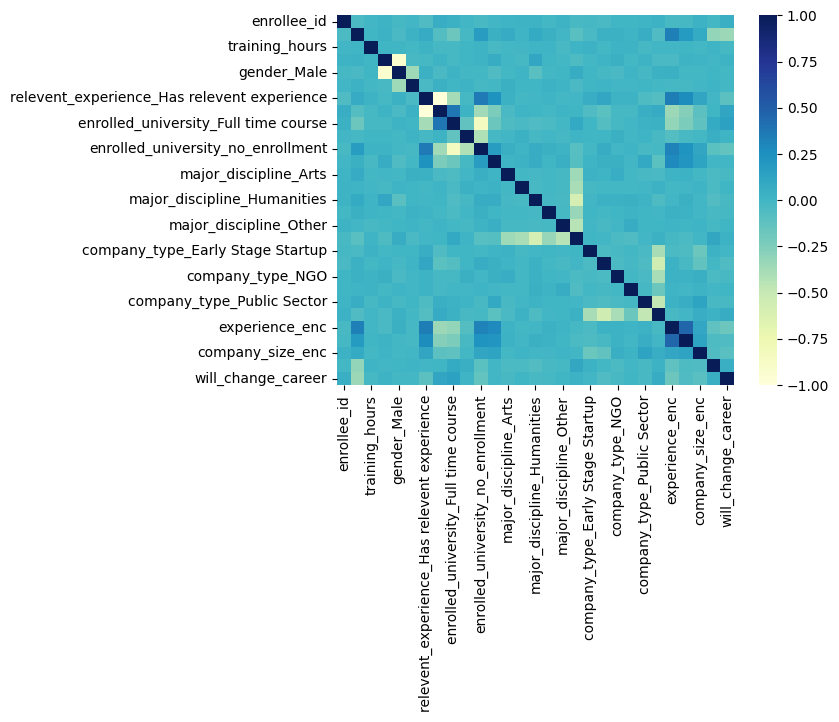

In [42]:
sns.heatmap(dataset_corr, cmap = 'YlGnBu')

# **Balance / Imbalance check of dataset**

Text(0.5, 1.0, 'Class Distribution of Target Feature (will_change_career)')

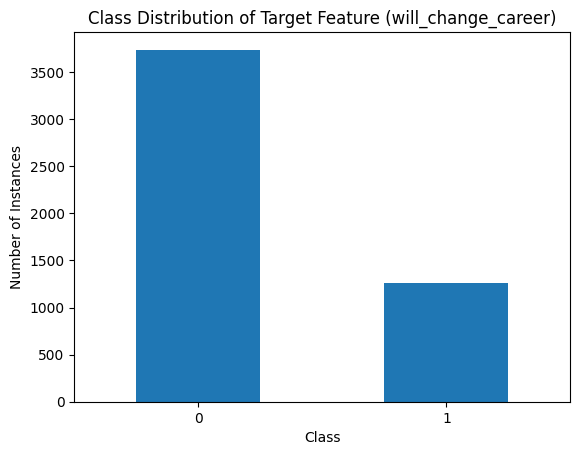

In [43]:
dataset["will_change_career"].value_counts().sort_index().plot(kind="bar", xlabel="Class",ylabel='Number of Instances', rot=0,)
plt.title("Class Distribution of Target Feature (will_change_career)")

# plt.show()

# **Next er code gula shuru koriani ekhono, so ignore **

### **Descriptive Analysis**
#### In descriptive Analysis we analysis each variable separately to get inference about the feature.
### **Summary satistics of Numerical Features**

In [44]:
# # Transposed stats for numerical features
numerical_data.describe().T

,count,mean,std,min,25%,50%,75%,max
enrollee_id,5000.0,17022.88300,9656.969716,7.000,8736.500,17068.000,25389.25,33380.000
city_development_index,5000.0,0.82941,0.122429,0.448,0.743,0.903,0.92,0.949
training_hours,5000.0,65.02720,59.946693,1.000,23.000,47.000,88.00,336.000
will_change_career,5000.0,0.25240,0.434433,0.000,0.000,0.000,1.00,1.000


### **Summary satistics of Categorical features**

In [45]:
# Transposed stats for categorical features

categorical_data.describe().T

,count,unique,top,freq
city,5000,113,city_103,1163
gender,3887,3,Male,3507
relevent_experience,5000,2,Has relevent experience,3598
enrolled_university,4893,3,no_enrollment,3571
education_level,4882,5,Graduate,3037
major_discipline,4276,6,STEM,3786
experience,4989,22,>20,859
company_size,3429,8,50-99,813
company_type,3379,6,Pvt Ltd,2550
last_new_job,4896,6,1,2094


### **Variance of each numerical features**

In [46]:
numerical_data.var()

,0
enrollee_id,9.325706e+07
city_development_index,1.498895e-02
training_hours,3.593606e+03
will_change_career,1.887320e-01


In [47]:
dataset.var()

,0
enrollee_id,9.325706e+07
city_development_index,1.498895e-02
training_hours,3.593606e+03
gender_Female,6.148266e-02
gender_Male,7.023805e-02
gender_Other,1.009798e-02
relevent_experience_Has relevent experience,2.018162e-01
relevent_experience_No relevent experience,2.018162e-01
enrolled_university_Full time course,1.634791e-01
enrolled_university_Part time course,5.517708e-02


In [48]:
numerical_data.skew()

,0
enrollee_id,-0.022808
city_development_index,-1.013328
training_hours,1.853677
will_change_career,1.140333


In [49]:
dataset.skew()

,0
enrollee_id,-0.022808
city_development_index,-1.013328
training_hours,1.853677
gender_Female,3.503622
gender_Male,-3.200983
gender_Other,9.752260
relevent_experience_Has relevent experience,-0.978043
relevent_experience_No relevent experience,0.978043
enrolled_university_Full time course,1.455846
enrolled_university_Part time course,3.759731


### **Skew in numerical features**

📐 What is Skewness?
Skewness measures the asymmetry of the distribution of a dataset.

Skewness = 0 → Perfectly symmetrical (e.g., normal distribution)

Skewness < 0 → Left-skewed (long tail on the left)

Skewness > 0 → Right-skewed (long tail on the right)

It helps you understand how balanced your data is and whether transformations are needed.

📊 Interpretation of Skewness Values:

Skewness Value	Interpretation

~ 0	Symmetrical (normal-ish)

0 to ±0.5	Fairly symmetrical

±0.5 to ±1	Moderately skewed

greater than ±1	Highly skewed

###**Skewness Interpretation**

*ID (0.448): Fairly symmetrical – no strong skew.

*CREDIT_SCORE (-0.226): Slightly left-skewed – not a concern.

*VEHICLE_OWNERSHIP (-1.729): Highly left-skewed – most values are 1 or 0; likely a categorical variable.

*MARRIED (-0.341): Slightly left-skewed – not a big issue.

*CHILDREN (-0.080): Almost symmetrical – no transformation needed.

*POSTAL_CODE (2.987): Strong right-skew – likely due to many unique codes; should be treated as categorical.

*ANNUAL_MILEAGE (-0.510): Moderately left-skewed – may benefit from transformation.

*SPEEDING_VIOLATIONS (3.900): Highly right-skewed – most people have few or no violations; some have many.

*DUIS (5.609): Extremely right-skewed – majority have zero DUIs; a few have multiple.

*PAST_ACCIDENTS (4.346): Strong right-skew – most have few accidents; some have many.

*OUTCOME (0.313): Fairly symmetrical – distribution looks balanced.



### **Histograms and Box Plot**
#### To find the distributions and outlier in the each feature

In [50]:
dataset

,enrollee_id,city_development_index,training_hours,gender_Female,gender_Male,gender_Other,relevent_experience_Has relevent experience,relevent_experience_No relevent experience,enrolled_university_Full time course,enrolled_university_Part time course,...,company_type_Funded Startup,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd,experience_enc,last_new_job_enc,company_size_enc,city_enc,will_change_career
0,8949,0.920,36,False,True,False,True,False,False,False,...,False,False,False,False,True,21,1,3,5,1
1,29725,0.776,47,False,True,False,False,True,False,False,...,False,False,False,False,True,15,5,3,68,0
2,11561,0.624,83,False,True,False,False,True,True,False,...,False,False,False,False,True,5,0,3,56,0
3,33241,0.789,52,False,True,False,False,True,False,False,...,False,False,False,False,True,0,0,3,13,1
4,666,0.767,8,False,True,False,True,False,False,False,...,True,False,False,False,False,21,4,3,46,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,7892,0.624,114,True,False,False,True,False,False,False,...,False,False,False,False,True,3,1,4,56,1
4996,19768,0.624,64,False,True,False,False,True,False,False,...,False,False,False,False,True,3,1,4,56,1
4997,33180,0.910,89,False,True,False,False,True,False,False,...,False,False,False,False,True,21,5,7,44,0
4998,13215,0.920,20,True,False,False,True,False,False,False,...,False,False,False,False,True,10,5,8,5,1


# **Histogram of all the features**

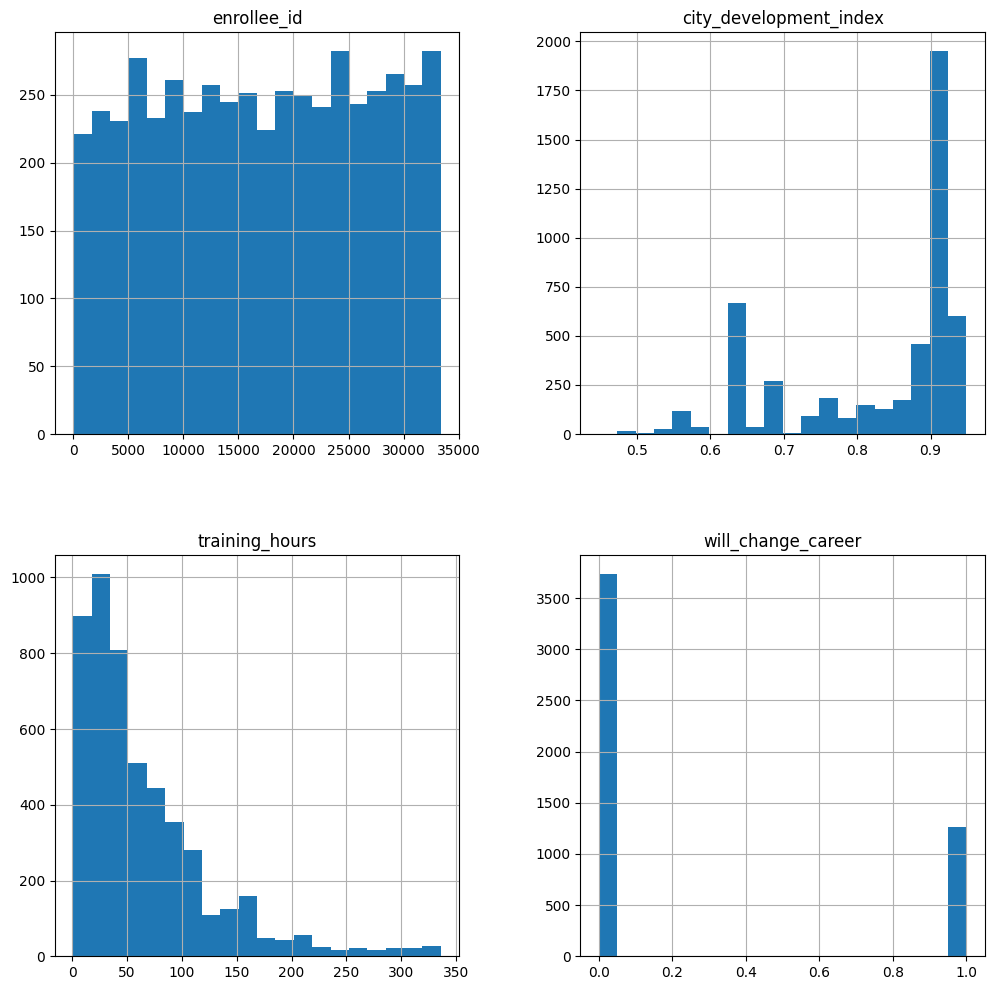

In [51]:
numerical_data.hist(figsize=(12,12),bins=20)
plt.show()

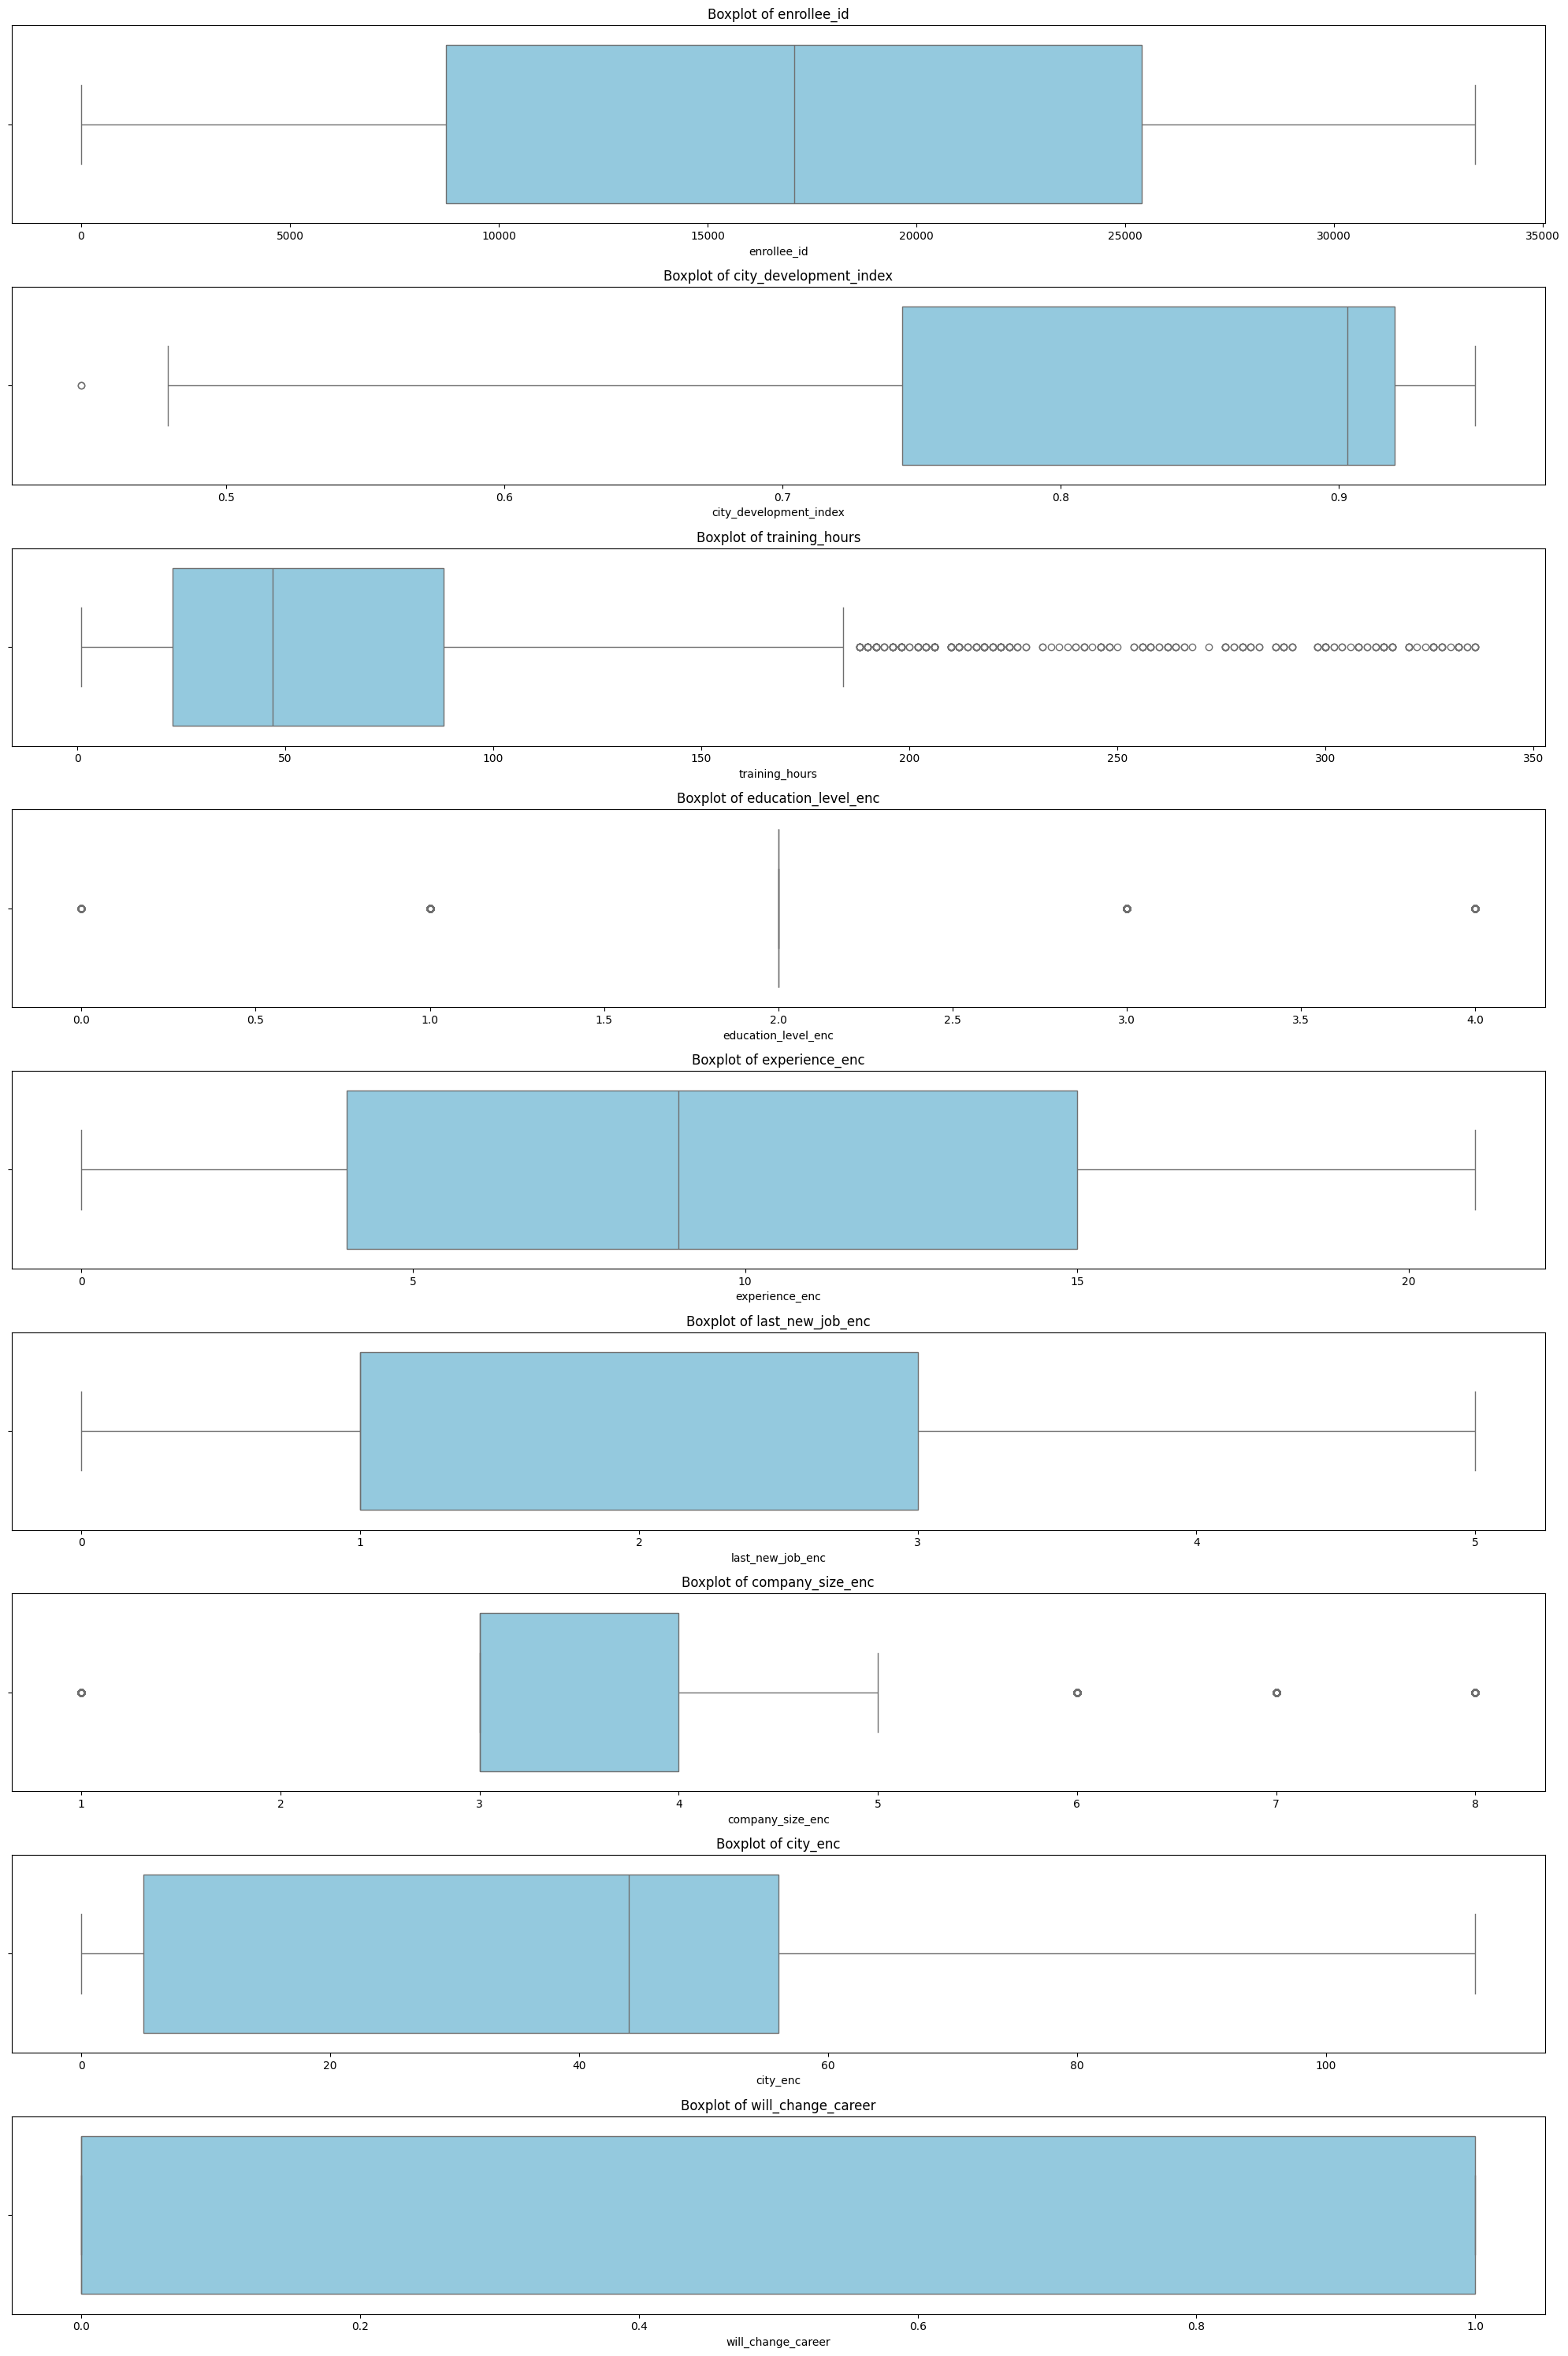

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numerical columns for boxplot analysis
numeric_cols = dataset.select_dtypes(include=['int64', 'float64']).columns

# Set up the figure
plt.figure(figsize=(20, 30))

# Plot boxplots for each numerical feature including the target variable 'OUTCOME'
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols), 1, i)
    sns.boxplot(x=dataset[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontsize=12)
    plt.tight_layout()

plt.show()

In [53]:
dataset

,enrollee_id,city_development_index,training_hours,gender_Female,gender_Male,gender_Other,relevent_experience_Has relevent experience,relevent_experience_No relevent experience,enrolled_university_Full time course,enrolled_university_Part time course,...,company_type_Funded Startup,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd,experience_enc,last_new_job_enc,company_size_enc,city_enc,will_change_career
0,8949,0.920,36,False,True,False,True,False,False,False,...,False,False,False,False,True,21,1,3,5,1
1,29725,0.776,47,False,True,False,False,True,False,False,...,False,False,False,False,True,15,5,3,68,0
2,11561,0.624,83,False,True,False,False,True,True,False,...,False,False,False,False,True,5,0,3,56,0
3,33241,0.789,52,False,True,False,False,True,False,False,...,False,False,False,False,True,0,0,3,13,1
4,666,0.767,8,False,True,False,True,False,False,False,...,True,False,False,False,False,21,4,3,46,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,7892,0.624,114,True,False,False,True,False,False,False,...,False,False,False,False,True,3,1,4,56,1
4996,19768,0.624,64,False,True,False,False,True,False,False,...,False,False,False,False,True,3,1,4,56,1
4997,33180,0.910,89,False,True,False,False,True,False,False,...,False,False,False,False,True,21,5,7,44,0
4998,13215,0.920,20,True,False,False,True,False,False,False,...,False,False,False,False,True,10,5,8,5,1


### **Number Unique values in each feature**

In [54]:
numerical_data.nunique()

,0
enrollee_id,5000
city_development_index,85
training_hours,238
will_change_career,2


### **Missing Values**

In [55]:
numerical_data.isnull().sum()

,0
enrollee_id,0
city_development_index,0
training_hours,0
will_change_career,0


### **Categorical Features**


#### **No of unique values in each categorical feature**

In [56]:
# unique values counts
unique_counts=categorical_data.nunique()
print(unique_counts)

city                   113
gender                   3
relevent_experience      2
enrolled_university      3
education_level          5
major_discipline         6
experience              22
company_size             8
company_type             6
last_new_job             6
dtype: int64


### **Barplot of unique value counts in every categorical features**

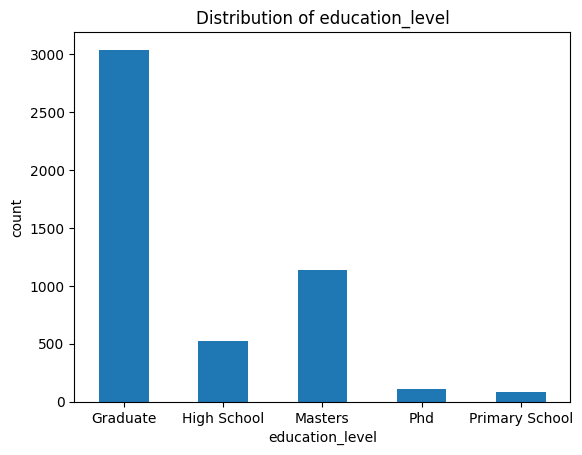

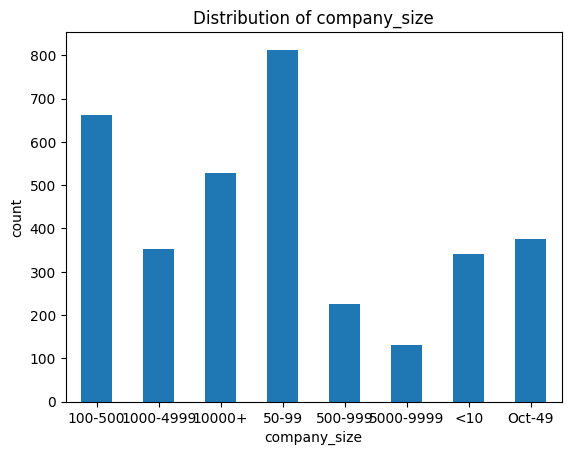

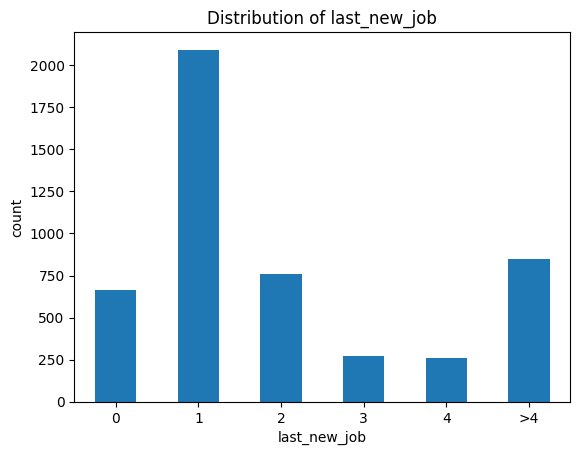

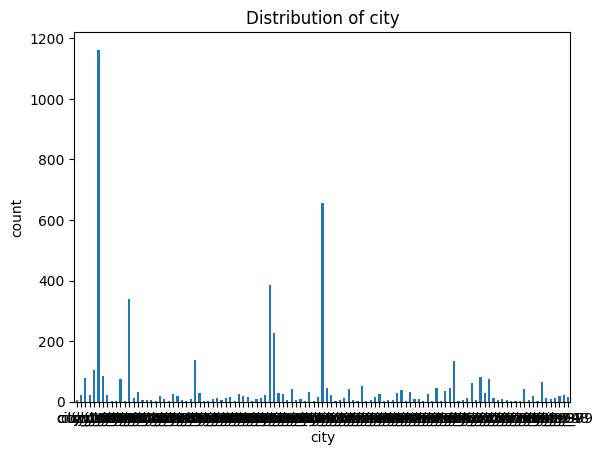

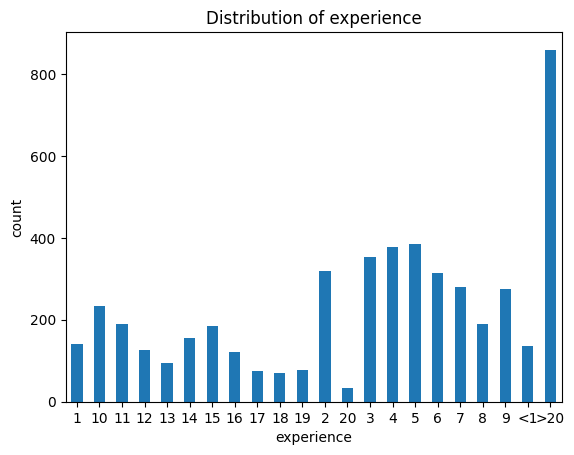

In [57]:
for col in categorical_features:
    plt.title(f'Distribution of {col}')
    categorical_data[col].value_counts().sort_index().plot(kind='bar', rot=0, xlabel=col,ylabel='count')
    plt.show()

### **Correlation Analysis**
### **Correlation matrix of whole dataset**

In [58]:
# Calculate the correlation matrix
correlation_matrix = numerical_data.corr()
correlation_matrix


,enrollee_id,city_development_index,training_hours,will_change_career
enrollee_id,1.000000,-0.039610,-0.004381,0.049445
city_development_index,-0.039610,1.000000,0.004717,-0.346808
training_hours,-0.004381,0.004717,1.000000,-0.022170
will_change_career,0.049445,-0.346808,-0.022170,1.000000


### **Correlation Heatmap plot of whole dataset**

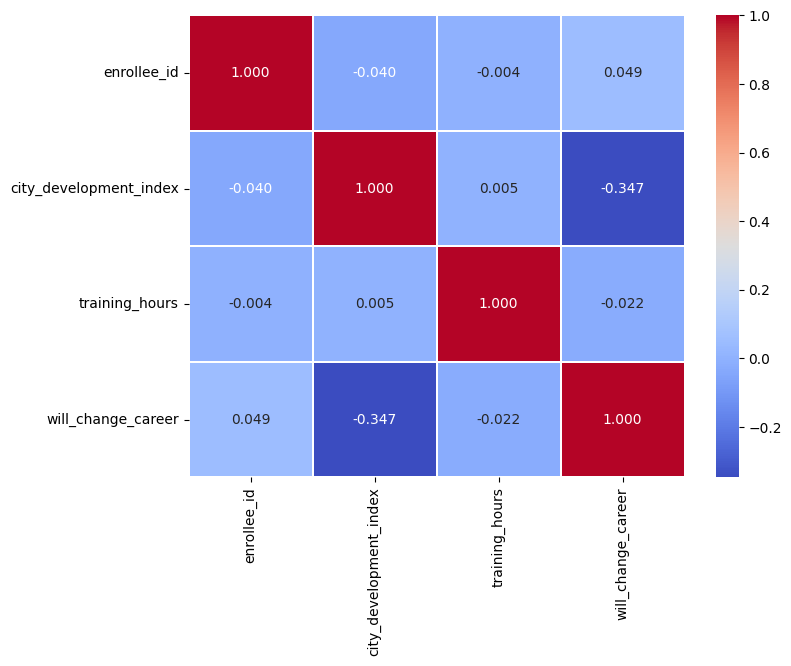

In [59]:
# Plotting the heatmap for correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.3)
plt.show()

### **Generating correlation plot between features and target variable using different method**

#### **Correlation plot between numerical features and target**

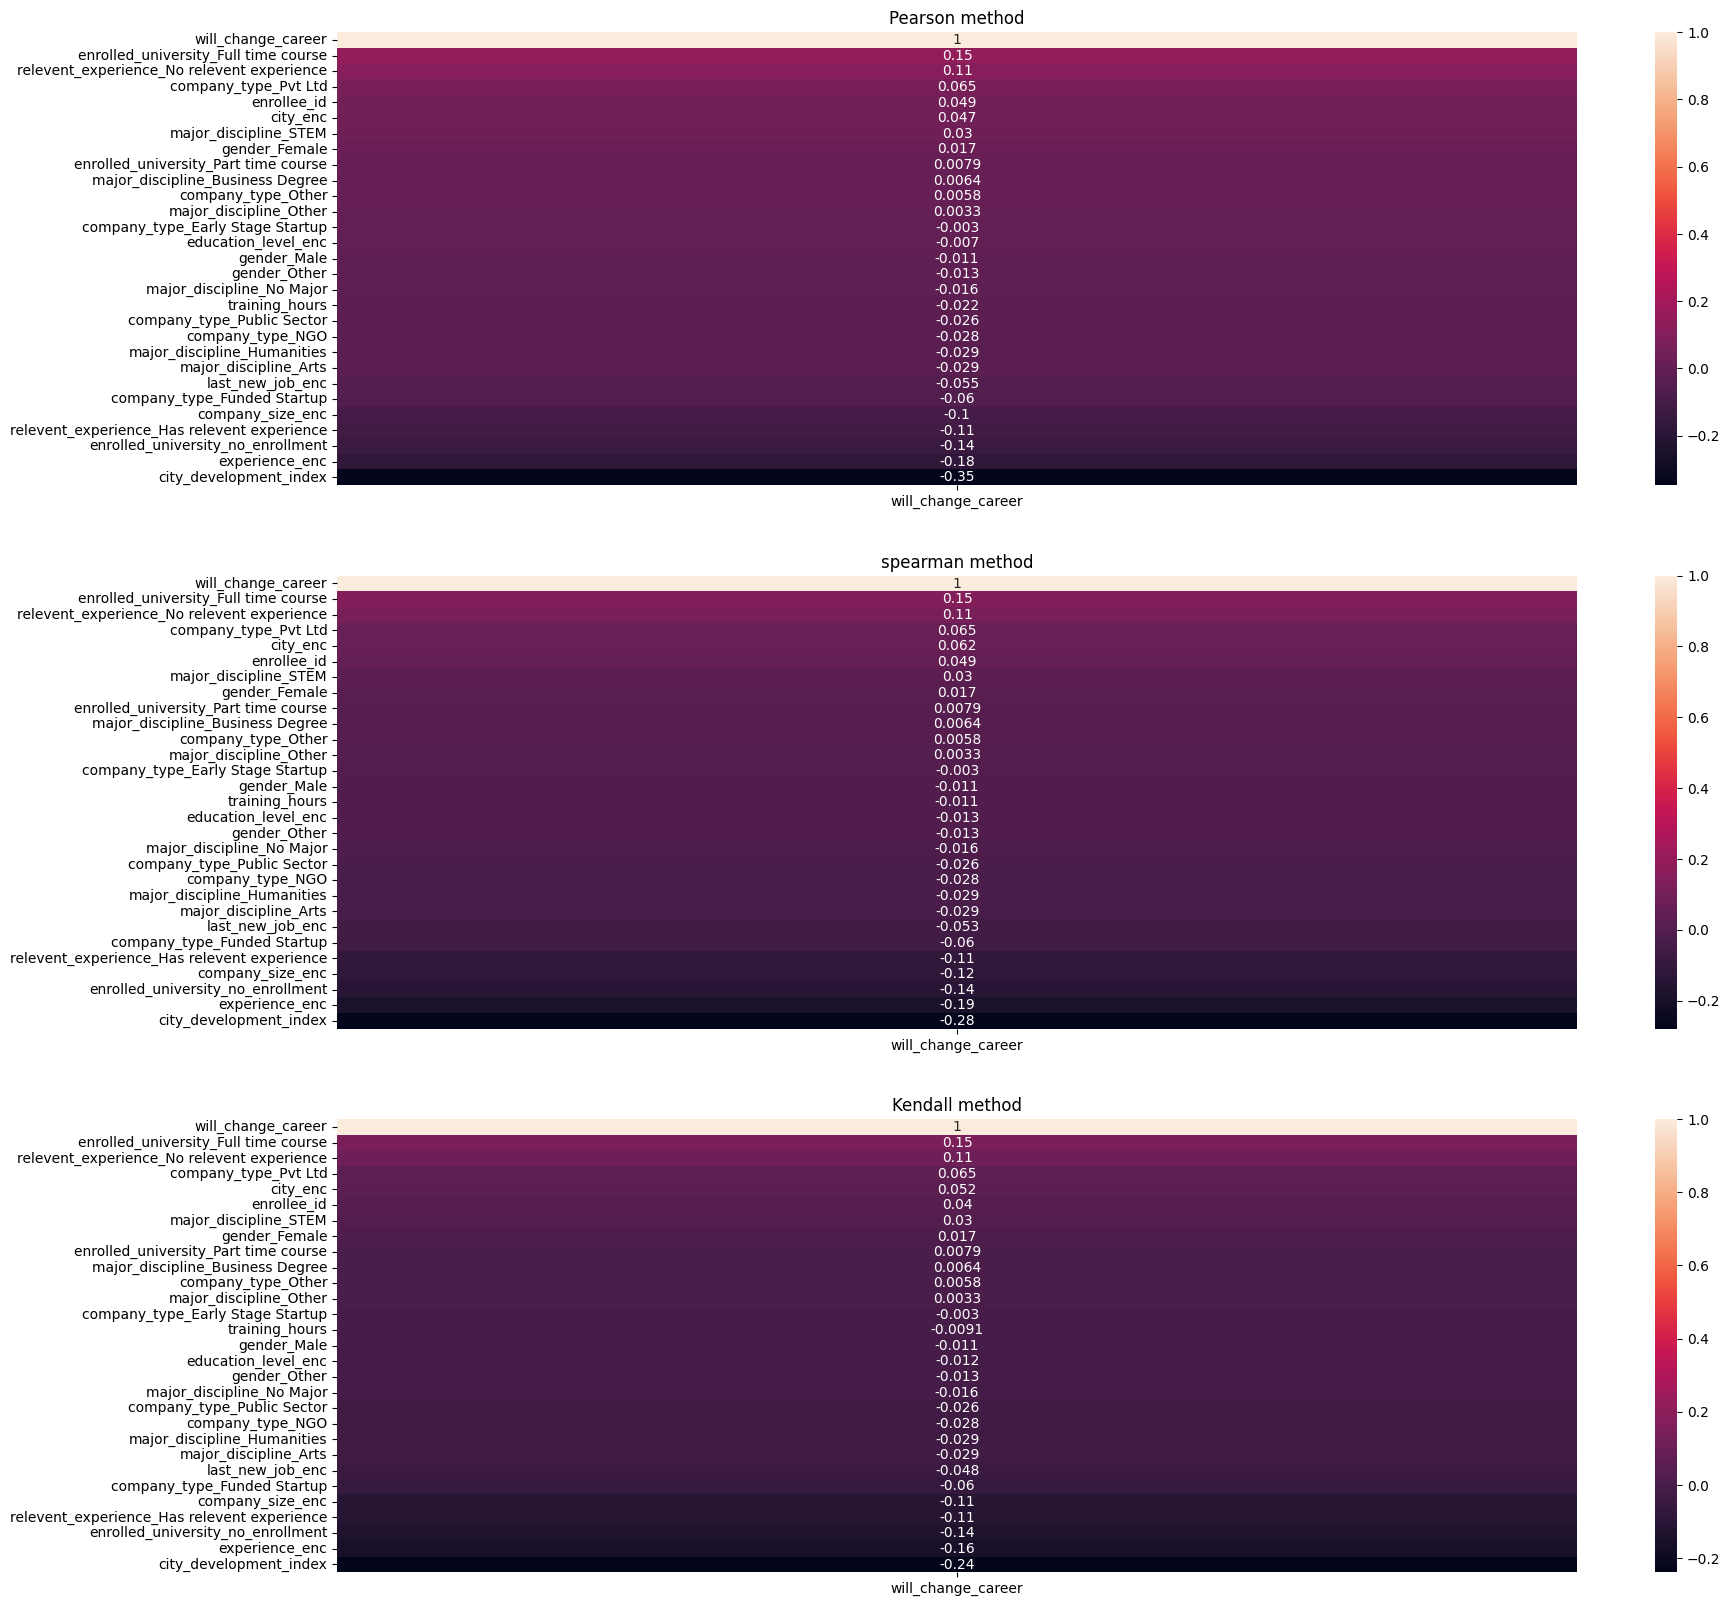

In [60]:
fig, ax = plt.subplots(3,1, figsize=(20, 20))
## Correlation coefficient using different methods
corr1 = dataset.corr('pearson')[['will_change_career']].sort_values(by='will_change_career', ascending=False)
corr2 = dataset.corr('spearman')[['will_change_career']].sort_values(by='will_change_career', ascending=False)
corr3 = dataset.corr('kendall')[['will_change_career']].sort_values(by='will_change_career', ascending=False)

#setting titles for each plot
ax[0].set_title('Pearson method')
ax[1].set_title('spearman method')
ax[2].set_title('Kendall method')

## Generating heatmaps of each methods
sns.heatmap(corr1, ax=ax[0], annot=True)
sns.heatmap(corr2, ax=ax[1], annot=True)
sns.heatmap(corr3, ax=ax[2], annot=True)

plt.show()

### **Check imbalance in the data**
#### We have classification problem so we need to check the balance of the given data.

In [61]:
#check Imbalance in data

#group instances based on the classes in OUTCOME variable
class_counts=dataset.groupby("will_change_career").size()

columns=['outcome','count','percentage']
outcome=[0,1]
count=list()
percentage=list()

#Calculate the percentage of each value of the OUTCOME variable from total
for val in range(2):
    count.append(class_counts[val])
    percent=(class_counts[val]/105000)*100
    percentage.append(percent)

# Convert the calulated values into a dataframe
imbalance_df=pd.DataFrame(list(zip(outcome,count,percentage)),columns=columns)
imbalance_df

,outcome,count,percentage
0,0,3738,3.560000
1,1,1262,1.201905


### **Barplot of Outcome vs Percentage**

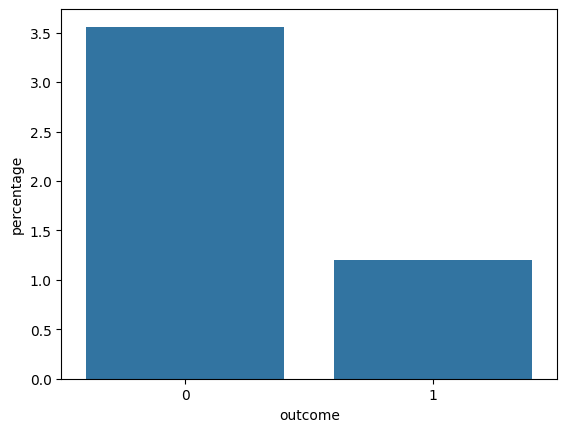

In [62]:
sns.barplot(data=imbalance_df,x=imbalance_df["outcome"],y=imbalance_df['percentage'])
plt.show()

### **Data visualization**
#### Some other visualizations of features to get more insights

### **Density plots of numerical features**

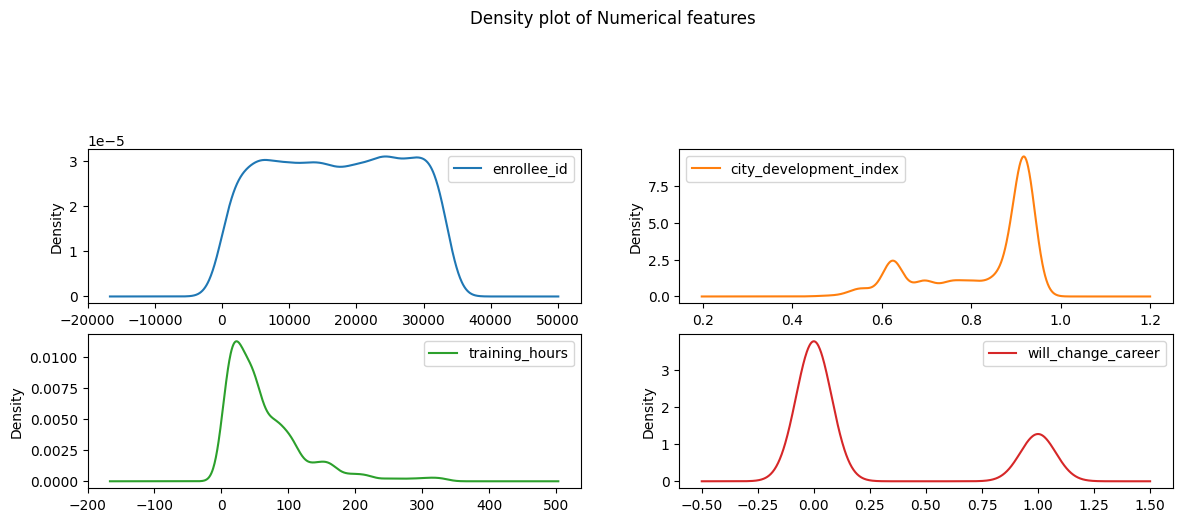

In [63]:
numerical_data.plot(kind='density',figsize=(14,14),subplots=True,layout=(6,2),title="Density plot of Numerical features",sharex=False)
plt.show()

### **SUMMARY**
#### Performed various exploratory data analysis techniques such as univariate, correlation, visualization on the given vehicle insurance dataset also found moderate imbalance in the given dataset. From the insights acquired through the analysis we will make better decisions when we do Machine learning model development.

# **Feature Scaling**

In [64]:
from sklearn.model_selection import train_test_split
x = dataset.drop(columns='will_change_career')  # only features
y = dataset['will_change_career']
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=.20, random_state=1, stratify=dataset['will_change_career'])
print(X_train.shape)
print(X_test.shape)

(4000, 28)
(1000, 28)


In [65]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaler.fit(X_train)

# transform train data
X_train_scaled = scaler.transform(X_train)

# transform test data
X_test_scaled = scaler.transform(X_test)

In [66]:
print("per-feature minimum after scaling:\n {}".format(
    X_train_scaled.min(axis=0)))
print("per-feature maximum after scaling:\n {}".format(
    X_train_scaled.max(axis=0)))

per-feature minimum after scaling:
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0.]
per-feature maximum after scaling:
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1.]


# **KNN**

In [67]:
# preprocessing before scaling
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier()

knn.fit(X_train, y_train)
knn_accuracy_1 = knn.score(X_test, y_test)
print("Test set accuracy without scaling: {:.2f}".format(knn_accuracy_1))

Test set accuracy without scaling: 0.70


In [68]:
# preprocessing after scaling
knn.fit(X_train_scaled, y_train)
knn_accuracy_2 = knn.score(X_test_scaled, y_test)
# scoring on the scaled test set
print("Test set accuracy after Min-Max Scaling: {:.2f}".format(
    knn_accuracy_2))

Test set accuracy after Min-Max Scaling: 0.74


In [69]:
accuracy = {}
accuracy['knn'] = max(knn_accuracy_1, knn_accuracy_2)

In [70]:
accuracy

{'knn': 0.742}

# **Logistic Regression (sclaer: minmax)**

In [71]:
# logistic regression before scaling
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(max_iter=9000, solver='saga')  # 'saga' also works for large datasets
log_reg.fit(X_train, y_train)

logreg_accuracy_1 = log_reg.score(X_test, y_test)
print("Test set accuracy (Logistic Regression): {:.2f}".format(logreg_accuracy_1))


Test set accuracy (Logistic Regression): 0.75


In [72]:
# logistic regression after scaling
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(max_iter=9000, solver='saga')
log_reg.fit(X_train_scaled, y_train)

logreg_accuracy_2 =  log_reg.score(X_test_scaled, y_test)
# Scoring on the scaled test set
print("Test set accuracy after Min-Max Scaling (Logistic Regression): {:.2f}".format(
   logreg_accuracy_2))

Test set accuracy after Min-Max Scaling (Logistic Regression): 0.77


In [73]:
accuracy["logreg"] = max(logreg_accuracy_1, logreg_accuracy_2)

# **Neural Network (scaler: standard)**

In [74]:
# before scaling feature
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(hidden_layer_sizes=(50, 30),  # 2 hidden layers with 50 and 30 neurons
                    activation='relu',
                    solver='adam',
                    max_iter=9000,
                    random_state=0)

# Train the model
mlp.fit(X_train, y_train)
nn_accuracy_1 = mlp.score(X_test, y_test)
# Evaluate
print("Test set accuracy with Neural Network: {:.2f}".format(nn_accuracy_1))

Test set accuracy with Neural Network: 0.75


In [75]:
## after scaling feature
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler # cuz it works better for relu
scaler = StandardScaler()
# transform train data
X_train_scaled = scaler.fit_transform(X_train)

# transform test data
X_test_scaled = scaler.transform(X_test)

mlp = MLPClassifier(hidden_layer_sizes=(50, 30),  # 2 hidden layers with 50 and 30 neurons
                    activation='relu',
                    solver='adam',
                    max_iter=9000,
                    random_state=0)

# Train the model
mlp.fit(X_train_scaled, y_train)
nn_accuracy_2 = mlp.score(X_test_scaled, y_test)
# Evaluate
print("Test set accuracy with Neural Network: {:.2f}".format(nn_accuracy_2))

Test set accuracy with Neural Network: 0.71


In [76]:
accuracy["nn"] = max(nn_accuracy_1, nn_accuracy_2)

# **Decision Tree**

(4000, 28)
(1000, 28)


[Text(0.3795392897134152, 0.9814814814814815, 'x[1] <= 0.632\ngini = 0.377\nsamples = 4000\nvalue = [2990, 1010]'),
 Text(0.09915760341813945, 0.9444444444444444, 'x[25] <= 0.5\ngini = 0.468\nsamples = 684\nvalue = [255.0, 429.0]'),
 Text(0.23934844656577733, 0.962962962962963, 'True  '),
 Text(0.019882501456593513, 0.9074074074074074, 'x[26] <= 2.0\ngini = 0.496\nsamples = 154\nvalue = [70, 84]'),
 Text(0.018328801709069722, 0.8703703703703703, 'gini = 0.0\nsamples = 5\nvalue = [0, 5]'),
 Text(0.021436201204117305, 0.8703703703703703, 'x[0] <= 6668.0\ngini = 0.498\nsamples = 149\nvalue = [70, 79]'),
 Text(0.006214798990095164, 0.8333333333333334, 'x[7] <= 0.5\ngini = 0.444\nsamples = 24\nvalue = [16, 8]'),
 Text(0.003107399495047582, 0.7962962962962963, 'x[24] <= 15.5\ngini = 0.278\nsamples = 6\nvalue = [1, 5]'),
 Text(0.001553699747523791, 0.7592592592592593, 'gini = 0.0\nsamples = 5\nvalue = [0, 5]'),
 Text(0.004661099242571373, 0.7592592592592593, 'gini = 0.0\nsamples = 1\nvalue = 

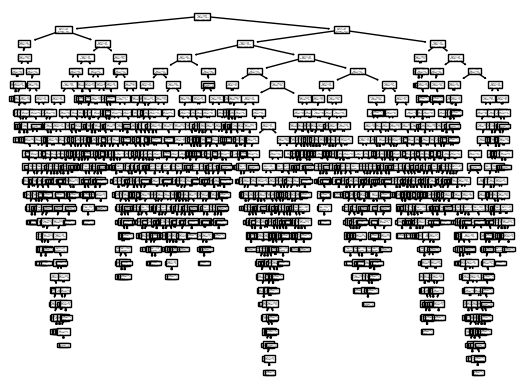

In [77]:
from sklearn import tree

from sklearn.model_selection import train_test_split
x = dataset.drop(columns='will_change_career')  # only features
y = dataset['will_change_career']
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=.20, random_state=1, stratify=dataset['will_change_career'])
print(X_train.shape)
print(X_test.shape)
dt = tree.DecisionTreeClassifier()
dt = dt.fit(X_train, y_train)

tree.plot_tree(dt)

In [78]:
# accuracy calculation
from sklearn.metrics import accuracy_score
y_pred = dt.predict(X_test)

# Accuracy
acc = accuracy_score(y_test, y_pred)
print("Decision Tree Accuracy:", acc)

Decision Tree Accuracy: 0.706


In [79]:
accuracy["dt"] = acc

In [80]:
print(accuracy)

{'knn': 0.742, 'logreg': 0.771, 'nn': 0.747, 'dt': 0.706}


# **Unsupervised**

In [81]:
# K_Means_cluster
from sklearn.cluster import KMeans

def implement_KMC(df_temp,cluster_num):
  km = KMeans(n_clusters=cluster_num)  #defining the cluster number
  y_predicted = km.fit_predict(df_temp[df_temp.columns])
  return km,y_predicted #returns the model and the predicted assigned cluster to each entry

cluster = 2
dataset_kmeans = x
km,y_predicted = implement_KMC(dataset_kmeans,cluster)  ##stores the model and the predicted values
dataset_kmeans["kmeans_cluster"]=y_predicted
dataset_kmeans.head(10)

,enrollee_id,city_development_index,training_hours,gender_Female,gender_Male,gender_Other,relevent_experience_Has relevent experience,relevent_experience_No relevent experience,enrolled_university_Full time course,enrolled_university_Part time course,...,company_type_Funded Startup,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd,experience_enc,last_new_job_enc,company_size_enc,city_enc,kmeans_cluster
0,8949,0.920,36,False,True,False,True,False,False,False,...,False,False,False,False,True,21,1,3,5,1
1,29725,0.776,47,False,True,False,False,True,False,False,...,False,False,False,False,True,15,5,3,68,0
2,11561,0.624,83,False,True,False,False,True,True,False,...,False,False,False,False,True,5,0,3,56,1
3,33241,0.789,52,False,True,False,False,True,False,False,...,False,False,False,False,True,0,0,3,13,0
4,666,0.767,8,False,True,False,True,False,False,False,...,True,False,False,False,False,21,4,3,46,1
5,21651,0.764,24,False,True,False,True,False,False,True,...,False,False,False,False,True,11,1,3,51,0
6,28806,0.920,24,False,True,False,True,False,False,False,...,True,False,False,False,False,5,1,3,45,0
7,402,0.762,18,False,True,False,True,False,False,False,...,False,False,False,False,True,13,5,1,74,1
8,27107,0.920,46,False,True,False,True,False,False,False,...,False,False,False,False,True,7,1,3,5,0
9,699,0.920,123,False,True,False,True,False,False,False,...,False,False,False,False,True,17,5,8,5,1


# **plotting the clusters by DIMENSIONALITY REDUCTION (PCA)
cuz it has 28 features, hence 28-D, impossible to visualize
**

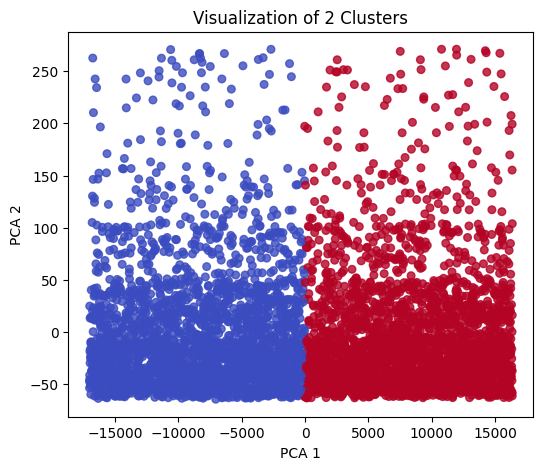

In [82]:
## before scaling

#Plot the 2 clusters with different color from the prediciton value
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Run KMeans with 2 clusters
kmeans = KMeans(n_clusters=2, random_state=1, n_init=10)
cluster_label = kmeans.fit_predict(x)   # <-- this creates the 'labels' array

# 3. Reduce to 2D for visualization
pca = PCA(n_components=2)
X_2d = pca.fit_transform(x)

# 4. Plot clusters
plt.figure(figsize=(6,5))
plt.scatter(X_2d[:,0], X_2d[:,1], c=cluster_label, cmap='coolwarm', s=30, alpha=0.8)
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Visualization of 2 Clusters")
plt.show()


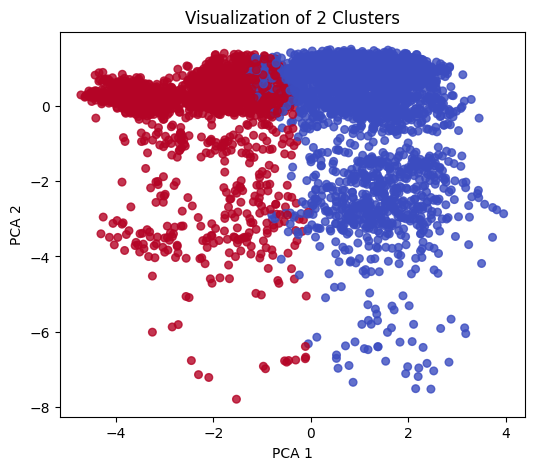

In [83]:
# after scaling
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(x)

# 2. Run KMeans with 2 clusters
kmeans = KMeans(n_clusters=2, random_state=1, n_init=10)
cluster_label = kmeans.fit_predict(X_scaled)   # <-- this creates the 'labels' array

# 3. Reduce to 2D for visualization
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

# 4. Plot clusters
plt.figure(figsize=(6,5))
plt.scatter(X_2d[:,0], X_2d[:,1], c=cluster_label, cmap='coolwarm', s=30, alpha=0.8)
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Visualization of 2 Clusters")
plt.show()


In [84]:
#mapping their behavior pattern to give them a categorization and adding it into the dataframe

label_map = {0: 'cluster_1', 1: 'cluster_2'}
dataset_kmeans['kmeans_cluster'] = dataset_kmeans['kmeans_cluster'].map(label_map)
display(dataset_kmeans.head(10))

,enrollee_id,city_development_index,training_hours,gender_Female,gender_Male,gender_Other,relevent_experience_Has relevent experience,relevent_experience_No relevent experience,enrolled_university_Full time course,enrolled_university_Part time course,...,company_type_Funded Startup,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd,experience_enc,last_new_job_enc,company_size_enc,city_enc,kmeans_cluster
0,8949,0.920,36,False,True,False,True,False,False,False,...,False,False,False,False,True,21,1,3,5,cluster_2
1,29725,0.776,47,False,True,False,False,True,False,False,...,False,False,False,False,True,15,5,3,68,cluster_1
2,11561,0.624,83,False,True,False,False,True,True,False,...,False,False,False,False,True,5,0,3,56,cluster_2
3,33241,0.789,52,False,True,False,False,True,False,False,...,False,False,False,False,True,0,0,3,13,cluster_1
4,666,0.767,8,False,True,False,True,False,False,False,...,True,False,False,False,False,21,4,3,46,cluster_2
5,21651,0.764,24,False,True,False,True,False,False,True,...,False,False,False,False,True,11,1,3,51,cluster_1
6,28806,0.920,24,False,True,False,True,False,False,False,...,True,False,False,False,False,5,1,3,45,cluster_1
7,402,0.762,18,False,True,False,True,False,False,False,...,False,False,False,False,True,13,5,1,74,cluster_2
8,27107,0.920,46,False,True,False,True,False,False,False,...,False,False,False,False,True,7,1,3,5,cluster_1
9,699,0.920,123,False,True,False,True,False,False,False,...,False,False,False,False,True,17,5,8,5,cluster_2


In [85]:
dataset_kmeans['kmeans_cluster'].value_counts()

,count
kmeans_cluster,
cluster_1,2513
cluster_2,2487


# **Model Comparison**

**accuracy of all models**

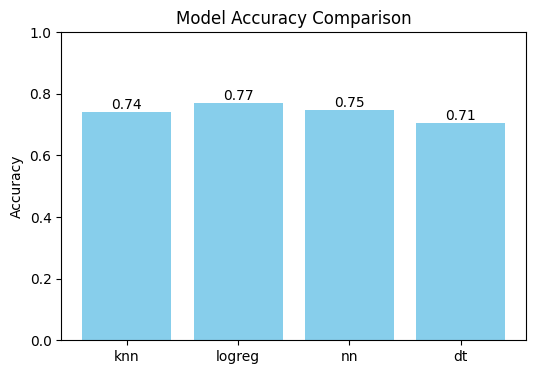

In [86]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.bar(accuracy.keys(), accuracy.values(), color="skyblue")

plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")
plt.ylim(0, 1)  # since accuracy is between 0 and 1

# add text labels on bars
for i, (model, acc) in enumerate(accuracy.items()):
    plt.text(i, acc + 0.01, f"{acc:.2f}", ha="center")

plt.show()


**Precision and Recall Comparison**

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(


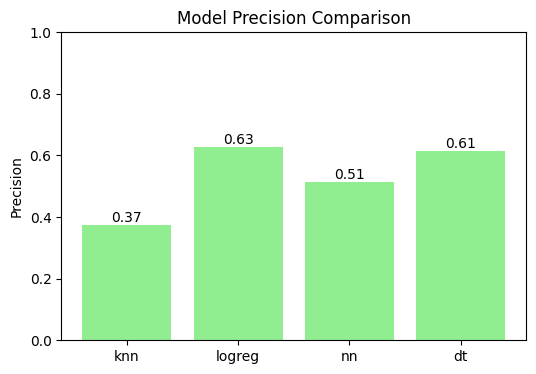

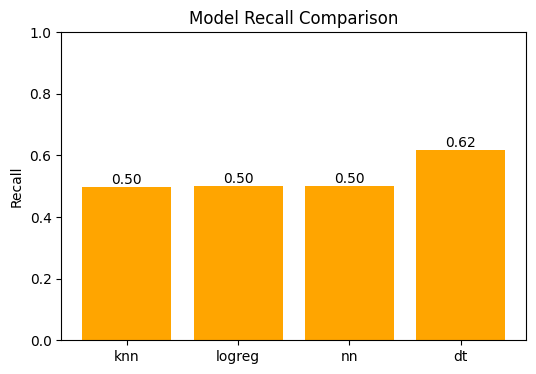

In [87]:
from sklearn.metrics import precision_score, recall_score
y_true = y_test

precisions = {}
recalls = {}

#knn
y_pred_knn = knn.predict(X_test)
precisions["knn"] = precision_score(y_true, y_pred_knn, average="macro")
recalls["knn"]    = recall_score(y_true, y_pred_knn, average="macro")

#logreg
y_pred_log = log_reg.predict(X_test)
precisions["logreg"] = precision_score(y_true, y_pred_log, average="macro")
recalls["logreg"]    = recall_score(y_true, y_pred_log, average="macro")

# mlp (nn)
y_pred_nn = mlp.predict(X_test)
precisions["nn"] = precision_score(y_true, y_pred_nn, average="macro")
recalls["nn"]    = recall_score(y_true, y_pred_nn, average="macro")

# dt
y_pred_dt = dt.predict(X_test)
precisions["dt"] = precision_score(y_true, y_pred_dt, average="macro")
recalls["dt"]    = recall_score(y_true, y_pred_dt, average="macro")

#Plot Precision
plt.figure(figsize=(6,4))
plt.bar(precisions.keys(), precisions.values(), color="lightgreen")
plt.ylabel("Precision")
plt.title("Model Precision Comparison")
plt.ylim(0,1)
for i, (model, prec) in enumerate(precisions.items()):
    plt.text(i, prec + 0.01, f"{prec:.2f}", ha="center")
plt.show()

#Plot Recall
plt.figure(figsize=(6,4))
plt.bar(recalls.keys(), recalls.values(), color="orange")
plt.ylabel("Recall")
plt.title("Model Recall Comparison")
plt.ylim(0,1)
for i, (model, rec) in enumerate(recalls.items()):
    plt.text(i, rec + 0.01, f"{rec:.2f}", ha="center")
plt.show()


**confusion matrix **

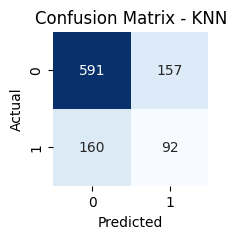

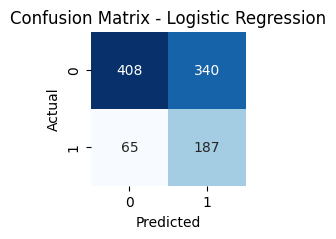

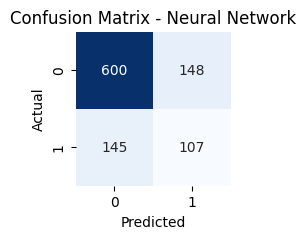

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


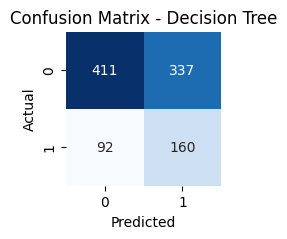

In [88]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

models = {
    "KNN": knn,
    "Logistic Regression": log_reg,
    "Neural Network": mlp,
    "Decision Tree": dt
}

for name, model in models.items():
    y_pred = model.predict(X_test_scaled) # over scaled obvi
    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Plot
    plt.figure(figsize=(2,2))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


**auc and roc **

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(


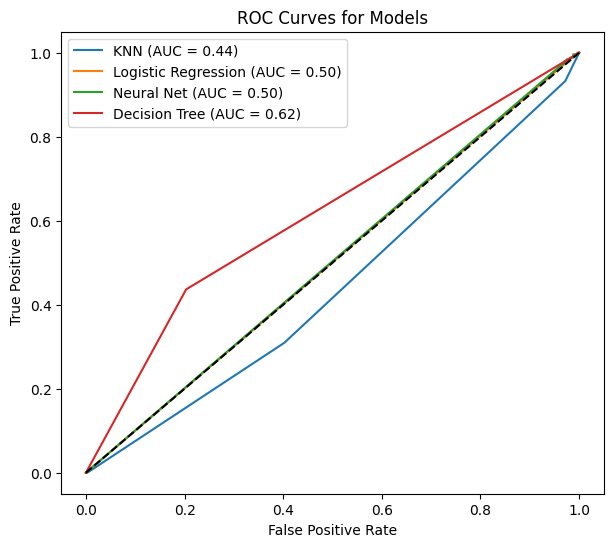

In [89]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

models = {
    "KNN": knn,
    "Logistic Regression": log_reg,
    "Neural Net": mlp,
    "Decision Tree": dt
}

plt.figure(figsize=(7,6))

for name, model in models.items():
    # check if model can output probabilities
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:,1]   # prob for cls1
    else:
        y_score = model.decision_function(X_test)    # fallback

    # ROC curve
    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc_score = roc_auc_score(y_test, y_score)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.2f})")

# reference line (random guess)
plt.plot([0,1], [0,1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Models")
plt.legend()
plt.show()


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(


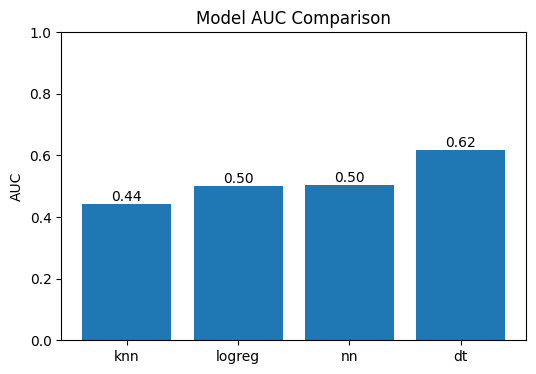

In [90]:
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

models = {
    "knn": knn,
    "logreg": log_reg,
    "nn": mlp,
    "dt": dt,
}

# compute AUCs (binary: uses class-1 scores)
aucs = {}
for name, model in models.items():
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)
    aucs[name] = roc_auc_score(y_test, y_score)

# bar chart
plt.figure(figsize=(6,4))
plt.bar(aucs.keys(), aucs.values())
plt.ylabel("AUC")
plt.title("Model AUC Comparison")
plt.ylim(0, 1)
for i, (model, aucv) in enumerate(aucs.items()):
    plt.text(i, aucv + 0.01, f"{aucv:.2f}", ha="center")
plt.show()
